# Burn a landscape with pyretechnics

How `fb_tools` drives the pyretechnics engine, from a LANDFIRE landscape to probabilistic fire surfaces:

1. **Static layers** — de-stack the LCP into engine-unit rasters.
2. **Potential fire behavior** — a deterministic, FlamMap-style map under one weather state.
3. **Weather episodes** — real historical windows at a named ERC severity, with spatially resolved HRRR wind.
4. **Ignition sites** — drawn from an FPA-FOD ignition density grid, as FSim does.
5. **One realization** — ignite, spread, look at arrival time and flame length; then a fuel-break
   counterfactual on one named fire over many spotting seeds.
6. **Ensemble** — every site × every episode → burn probability, arrival probability by day, expected firebrands.
7. **Diagnostics**, and 8. **clean-up** of the per-run rasters.

Runs in the `fb_pyre` env. Landscape: the `front_range` test AOI (pyrome 46, 3000 × 1000 cells at 30 m), downloaded
once with `lfps_request` into `data/spatial/mod/fuelscapes/front_range/`. Weather comes from the caches under
`data/weather/`. Products go to scratch (`$FB_PYRE_SCRATCH`, default `~/fb_scratch`); HRRR GRIB subsets go to the
shared cache every fb_tools HRRR fetch uses (`$FB_HRRR_CACHE`, default `~/fb_scratch/hrrr_cache`).

In [1]:
import json, os, time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd
import rasterio, rasterio.plot

import fb_tools
from fb_tools.models import pyre
from fb_tools.fuelscape import ignition_density_surface, sample_density_ignitions
from fb_tools.spread import (destack_lcp, select_episodes, load_rtma_hourly, write_episode_frames,
                             layer_bounds_lonlat, episode_wind_cube, write_wind_cube, load_wind_cube,
                             wind_cube_summary, weather_arrays, weather_from_scenario,
                             summarize_realization, summarize_runs, aggregate_realizations)
from fb_tools.weather import fetch_hrrr_wind_grid, dominant_wind_direction, default_hrrr_cache

REPO         = Path(fb_tools.__file__).resolve().parents[1]
LCP_FP       = next((REPO / "data/spatial/mod/fuelscapes/front_range").glob("LCP_front_range_LF*.tif"))
SCRATCH      = Path(os.environ.get("FB_PYRE_SCRATCH", Path.home() / "fb_scratch")) / "pyre_example"
ERC_DIR      = REPO / "data/weather/pyrome_erc"                       # GridMET ERC climatology (00a)
RTMA_DIR     = REPO / "data/weather/pyrome_emc/RTMA_MONTHLY"          # hourly T/RH, pyrome mean (00b)
WIND_DIR     = REPO / "data/weather/pyrome_emc/RTMA_WIND_MONTHLY"     # hourly u/v, pyrome mean (00b)
WINDCELL_DIR = REPO / "data/weather/pyrome_wind"                      # HRRR fire-hour wind climatology (00c)
FOD_FP       = Path("/Users/mcc/Library/CloudStorage/Box-Box/MCC/data/wildfire/FPA_FOD/"
                    "RDS-2013-0009/Data/FPA_FOD_20260615.gpkg")       # authoritative FPA-FOD, through 2024

"""
Model parameters
---
PYROME:
YEARS:
SEVERITY:
DURATION_DAYS:
"""
PYROME          = 46                  # Front Range Pyrome
YEARS           = range(2016, 2026)   # Fire weather range (HRRR is gap-free from 2016)
SEVERITY        = "p97"               # ERC percentile that day 1 of an episode must meet
DURATION_DAYS   = 7
EPISODE_POOL    = "fod"
N_EPISODES      = 5
N_IGNITIONS     = 10
FOD_MIN_CLASS   = "C"                 # FPA-FOD size classes >= this (C = 10 ac+) build the ignition density grid
IDG_BANDWIDTH_M = 10_000              # Gaussian kernel sd of the ignition density grid
CROWN_GATE      = 0.0                 # canopy-cover gate for crown fire (0.0 = off; stock engine 0.4)
N_WORKERS       = 4
SEED            = 617327

pyre.pyre_version_info()

{'pyretechnics_version': '2026.8.10+cfri1',
 'pyretechnics_pinned': '2026.8.10',
 'pyretechnics_patched': True,
 'crown_cover_threshold': 0.4,
 'python_version': '3.11.16',
 'numpy_version': '1.26.4',
 'scipy_version': '1.12.0',
 'platform': 'Darwin-arm64',
 'conda_env': 'fb_pyre'}

## 1. Static layers

`destack_lcp` writes one GeoTIFF per engine input, in engine units (slope as rise/run, canopy cover as a
fraction, heights in metres). `load_static_layers` reads them back as the arrays the cubes are built from.

In [2]:
layers = SCRATCH / "layers" / LCP_FP.stem
if not (layers / "fuel_model.tif").exists():
    destack_lcp(LCP_FP, layers)
static, TRANSFORM, CRS = pyre.load_static_layers(layers)
SHAPE = static["slope"].shape
print(SHAPE, CRS, f"{abs(TRANSFORM.a):.0f} m |", ", ".join(static))

(3000, 1000) EPSG:5070 30 m | slope, aspect, fuel_model, canopy_cover, canopy_height, canopy_base_height, canopy_bulk_density


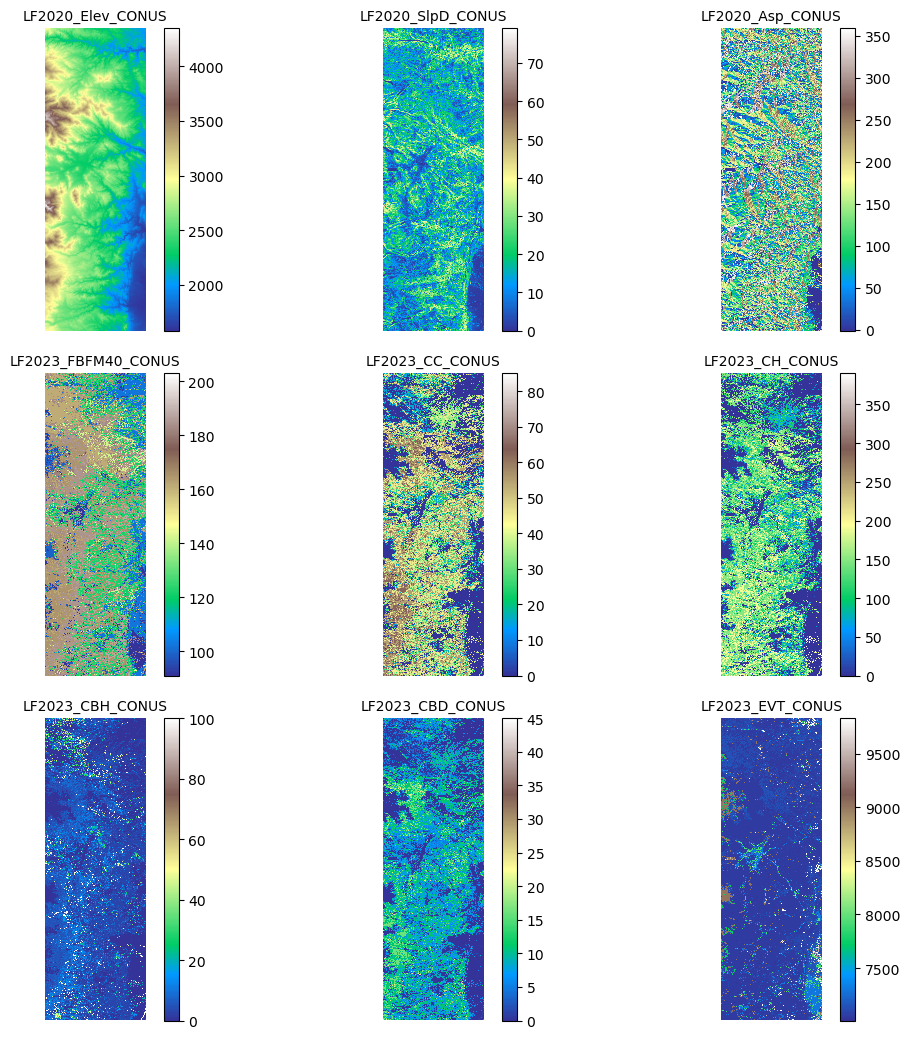

In [3]:
from fb_tools import plot_bands
fig, axes = plot_bands(LCP_FP)

## 2. Potential fire behavior (no spread)

A deterministic map from the engine's `burn_cells`: every cell burned as a head fire under one weather state.
Here the state is the pyrome's `p97` FlamMap scenario (RTMA dead fuel moisture, HRRR p97 wind speed), blowing
from the pyrome's dominant fire-hour direction — so the map is parameterized exactly like the FlamMap runs it
sits beside. `burn_landscape` writes flame length, fireline intensity, spread rate/direction and fire type.

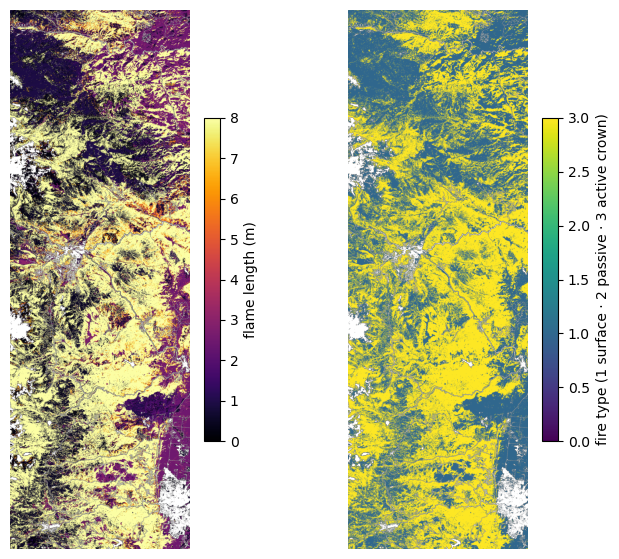

wind from 292° at 43 km/h | {'n_burnable': 2792165, 'crown_frac': 0.5272, 'wall_s': 2.1}


In [4]:
def show(ax, fp, label, *, mask_zero=False, **kw):
    """imshow one GeoTIFF band with a colorbar."""
    with rasterio.open(fp) as src:
        a = src.read(1)
        if mask_zero:
            a = np.where(a > 0, a, np.nan)
        im = ax.imshow(a, extent=rasterio.plot.plotting_extent(src), **kw)
    plt.colorbar(im, ax=ax, shrink=0.6, label=label); ax.set_axis_off()
    return ax

def zoom(ax, fp, margin_cells=60):
    """Limit the axes to the finite (burned) cells of a raster, plus a margin."""
    with rasterio.open(fp) as src:
        rr, cc = np.where(np.isfinite(src.read(1)))
        x0, y0 = src.xy(rr.max() + margin_cells, cc.min() - margin_cells)
        x1, y1 = src.xy(rr.min() - margin_cells, cc.max() + margin_cells)
    ax.set(xlim=(x0, x1), ylim=(y0, y1))

p97 = json.load(open(REPO / f"data/weather/flammap_rtma/pyrome_{PYROME}_flammap.json"))["scenarios"]["p97"]
WD_FROM = dominant_wind_direction(PYROME, WINDCELL_DIR)
scen = weather_from_scenario(p97, wind_from_deg=WD_FROM, tmp_c=30.0)
pot_dir = SCRATCH / f"potential_p97_wd{WD_FROM:.0f}"          # named by its inputs: a cached map is never stale
pot = pyre.burn_landscape(layers, scen, pot_dir, crown_gate=CROWN_GATE)

fig, axes = plt.subplots(1, 2, figsize=(8, 7))
show(axes[0], pot_dir / "flame_length.tif", "flame length (m)", cmap="inferno", vmin=0, vmax=8)
show(axes[1], pot_dir / "fire_type.tif", "fire type (1 surface · 2 passive · 3 active crown)",
     cmap="viridis", vmin=0, vmax=3)
plt.show()
print(f"wind from {WD_FROM:.0f}° at {scen['wind_speed_10m'][0]:.0f} km/h |",
      {k: pot[k] for k in ("n_burnable", "crown_frac", "wall_s")})

## 3. Weather episodes

An *episode* is a real historical window whose day-1 ERC meets the severity percentile of the pyrome's GridMET
climatology — nothing is scaled or offset, so each episode is nameable and keeps its diurnal cycle and
day-to-day autocorrelation. Hourly T/RH from the pyrome-mean RTMA record are turned into NFDRS dead fuel
moisture; the hourly frame is written in engine units (°C, km/h, moistures as fractions). Windows with an RTMA
gap longer than 3 h are never candidates.

[select_episodes] pool: 42 climatology window(s) at p97; rank = random


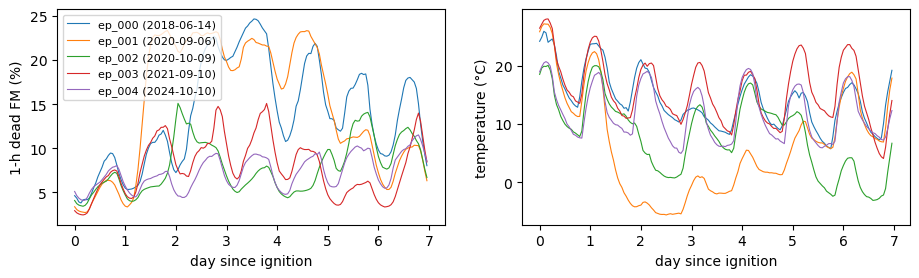

,episode_id,start_date,end_date,erc_day1,erc_mean,erc_threshold
0,ep_000,2018-06-14,2018-06-20,77.0,56.9,74.0
1,ep_001,2020-09-06,2020-09-12,80.0,45.7,74.0
2,ep_002,2020-10-09,2020-10-15,82.0,73.6,74.0
3,ep_003,2021-09-10,2021-09-16,76.0,65.7,74.0
4,ep_004,2024-10-10,2024-10-16,75.0,74.9,74.0


In [5]:
rtma = load_rtma_hourly(RTMA_DIR, PYROME, YEARS, wind_dir=WIND_DIR)
episodes = select_episodes(PYROME, ERC_DIR, severity=SEVERITY, n=N_EPISODES, duration_days=DURATION_DAYS,
                           years=YEARS, rtma_df=rtma, seed=SEED)
frames = write_episode_frames(episodes, rtma, SCRATCH / "episodes")          # {episode_id: hourly csv}

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
for eid, fp in frames.items():
    f = pd.read_csv(fp)
    axes[0].plot(f.hour / 24, f.fm1 * 100, lw=0.8, label=f"{eid} ({episodes.set_index('episode_id').start_date[eid]:%Y-%m-%d})")
    axes[1].plot(f.hour / 24, f.tmp_c, lw=0.8)
axes[0].set(ylabel="1-h dead FM (%)", xlabel="day since ignition"); axes[1].set(ylabel="temperature (°C)", xlabel="day since ignition")
axes[0].legend(fontsize=8); plt.show()
episodes[["episode_id", "start_date", "end_date", "erc_day1", "erc_mean", "erc_threshold"]]

+---
### 3b. Local wind

Any spatial mean of wind erases the gusts that drive spread: the pyrome-mean wind rarely exceeds 17 mph while
single 3 km HRRR cells in the same domain reach 30. So each episode's wind is a 3-D cube: HRRR 10 m U/V fetched
by HTTP byte range from AWS (~2 MB per hour, cached once for every fb_tools HRRR user), sampled nearest-cell onto
a block grid that divides the landscape exactly. The engine repeats each block over its 30 m cells; T/RH stay on
the pyrome-mean frame.

[fetch_hrrr_wind_grid] 168 h, 35x20 cells, 0 missing hour(s) interpolated


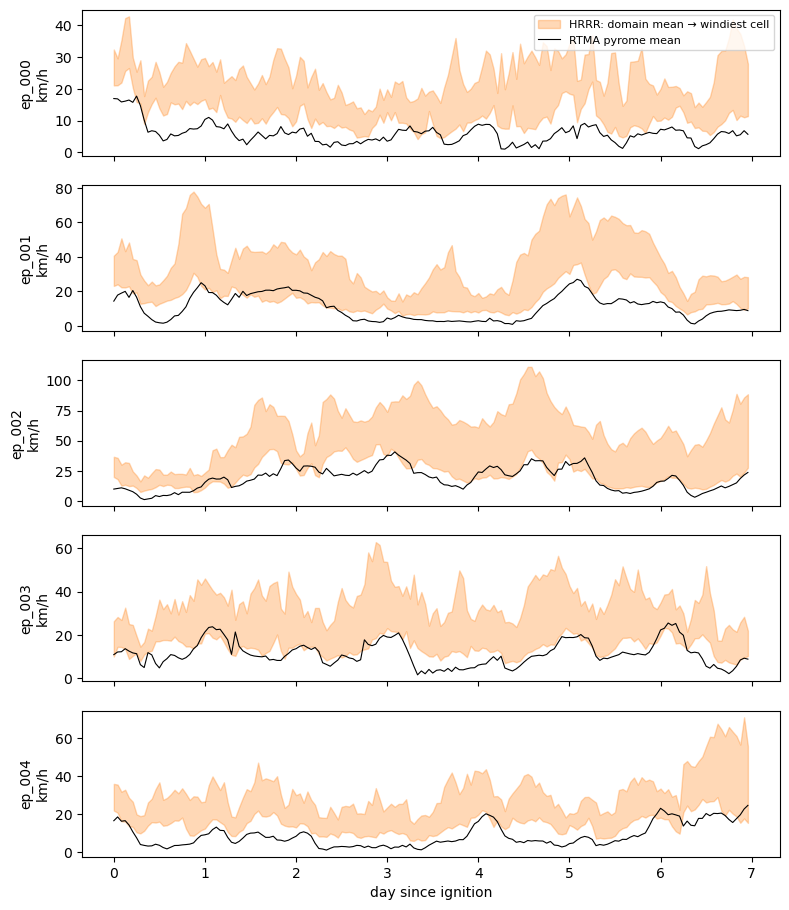

cube (168, 30, 10) | block (100, 100) cells = (3000.0, 3000.0) m | HRRR cache: /Users/mcc/fb_scratch/hrrr_cache


In [6]:
bounds = layer_bounds_lonlat(layers)
cubes = {}
for eid, fp in frames.items():
    times = pd.read_csv(fp, parse_dates=["datetime_utc"]).datetime_utc
    cube_fp = SCRATCH / "episodes" / f"{eid}_{times.iloc[0]:%Y%m%d}_wind.npz"   # dated: a re-selected ep_000 never reuses a stale cube
    if not cube_fp.exists():
        grid = fetch_hrrr_wind_grid(times, bounds, n_threads=2)              # -> default_hrrr_cache()
        write_wind_cube(cube_fp, episode_wind_cube(grid, TRANSFORM, CRS, SHAPE))
    cubes[eid] = cube_fp

fig, axes = plt.subplots(len(cubes), 1, figsize=(9, 2.2 * len(cubes)), sharex=True, squeeze=False)
for ax, (eid, fp) in zip(axes[:, 0], cubes.items()):
    s, f = wind_cube_summary(load_wind_cube(fp)), pd.read_csv(frames[eid])
    ax.fill_between(s.hour / 24, s.ws_mean, s.ws_max, color="C1", alpha=0.3, label="HRRR: domain mean → windiest cell")
    ax.plot(f.hour / 24, f.ws_kmh, color="k", lw=0.8, label="RTMA pyrome mean")
    ax.set(ylabel=f"{eid}\nkm/h")
axes[0, 0].legend(loc="upper right", fontsize=8); axes[-1, 0].set(xlabel="day since ignition"); plt.show()
c = load_wind_cube(next(iter(cubes.values())))
print("cube", c["wind_speed_10m"].shape, "| block", c["block"], "cells =", c["block_m"], "m | HRRR cache:", default_hrrr_cache())

## 4. Ignition sites from an ignition density grid

FSim does not place fires uniformly: it draws locations from an **ignition density grid** (IDG), a
kernel-smoothed surface of historical FPA-FOD ignitions masked to burnable fuel. `ignition_density_surface`
builds the same thing from the authoritative FOD (through 2024): fires of size class ≥ `FOD_MIN_CLASS` in and
around the landscape (points outside the domain still contribute smoothing mass at its edge), a Gaussian kernel
of `IDG_BANDWIDTH_M`, normalized to sum to 1 over burnable cells. `sample_density_ignitions` then draws
`N_IGNITIONS` **grid cells** ∝ density without replacement — any burnable cell that received kernel mass can be
drawn, so sites are *not* the historical points themselves — and writes each as a 10-acre day-1 footprint in its
own shapefile. Because sites are drawn ∝ density, every realization carries equal weight in the ensemble.

`FOD_MIN_CLASS` sets the smallest size class that builds the grid: `"C"` (10 ac+) keeps the places fires *grew*
rather than merely started; `"D"` (100 ac+, the setting above) leaves ~160 points in this window, so the kernel
is wide (10 km) or the surface turns into a few spikes. The class and kernel are stamped in the site table.

Two things FSim does that this example does not: the number of fires per simulated day is drawn from an
ERC-conditioned occurrence model (here the count is fixed), and ignitions are spread through a whole season
(here they all start on day 1 of a severe episode).

  [ignition_density_surface] bandwidth=10,000 m (4.0 cells), 219 points (70 inside the LCP), burnable-masked, normalized
  [write_ignition_shapefiles] 10 single-feature shapefile(s) → /Users/mcc/fb_scratch/pyre_example/ignitions
  [sample_density_ignitions] 10 site(s) drawn ∝ density (10.00 ac each) → /Users/mcc/fb_scratch/pyre_example/ignitions


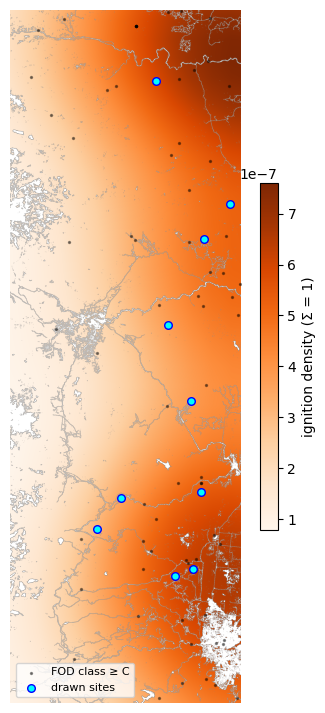

70 FOD fires inside the landscape (494 in the smoothing window); 10 sites drawn (10.00 ac each), w_i = 1/10


,geometry,ign_id,density,w_i,footprint_ac,path
0,"POLYGON ((-785916.503 1936740, -785916.537 193...",0,6.220843e-07,0.1,9.999,/Users/mcc/fb_scratch/pyre_example/ignitions/i...
1,"POLYGON ((-789216.503 1968420, -789216.537 196...",1,3.727042e-07,0.1,9.999,/Users/mcc/fb_scratch/pyre_example/ignitions/i...
2,"POLYGON ((-790746.503 2000160, -790746.537 200...",2,5.818217e-07,0.1,9.999,/Users/mcc/fb_scratch/pyre_example/ignitions/i...
3,"POLYGON ((-795366.503 1946010, -795366.537 194...",3,3.526415e-07,0.1,9.999,/Users/mcc/fb_scratch/pyre_example/ignitions/i...
4,"POLYGON ((-788286.503 1935870, -788286.537 193...",4,5.874634e-07,0.1,9.999,/Users/mcc/fb_scratch/pyre_example/ignitions/i...


In [7]:
with rasterio.open(LCP_FP) as src:
    B = src.bounds
box = gpd.GeoSeries.from_xy([B.left, B.right], [B.bottom, B.top], crs=CRS).to_crs(4269)
pad = 0.6                                                   # degrees, ~10 bandwidths: edge smoothing is honest
classes = ", ".join(repr(c) for c in "ABCDEFG" if c >= FOD_MIN_CLASS)
fod = gpd.read_file(FOD_FP, layer="Fires", where=f"FIRE_SIZE_CLASS IN ({classes})",
                    bbox=(box.x.min() - pad, box.y.min() - pad, box.x.max() + pad, box.y.max() + pad))
idg = ignition_density_surface(fod, LCP_FP, bandwidth_m=IDG_BANDWIDTH_M)
ign = sample_density_ignitions(idg, N_IGNITIONS, SCRATCH / "ignitions", seed=SEED)

fig, ax = plt.subplots(figsize=(5, 9))
im = ax.imshow(np.where(idg["density"] > 0, idg["density"], np.nan),
               extent=rasterio.plot.plotting_extent(idg["density"], idg["transform"]), cmap="Oranges")
fod.to_crs(CRS).cx[B.left:B.right, B.bottom:B.top].plot(ax=ax, markersize=2, color="k", alpha=0.4,
                                                        label=f"FOD class ≥ {FOD_MIN_CLASS}")
ign.centroid.plot(ax=ax, color="cyan", edgecolor="b", markersize=30, label="drawn sites")
ax.legend(loc="lower left", fontsize=8); ax.set_axis_off()
plt.colorbar(im, ax=ax, shrink=0.5, label="ignition density (Σ = 1)"); plt.show()
print(f"{idg['n_in_domain']} FOD fires inside the landscape ({len(fod)} in the smoothing window); "
      f"{len(ign)} sites drawn ({ign.footprint_ac.iloc[0]:.2f} ac each), w_i = 1/{len(ign)}")
ign.head()

## 5. One realization

`run_realization` takes one landscape, one weather set (hourly frame + wind cube) and one footprint, and writes
arrival time (minutes), fire type, spread rate/direction, fireline intensity and flame length as GeoTIFFs plus
a manifest that records the seed, engine build, crown gate and solver knobs. Spotting is on with the engine's
default parameters (`SPOT_CENTRAL`). It is a heavy tail: most seeds add little area, a few break out — so the
single run below is one draw, not the answer.

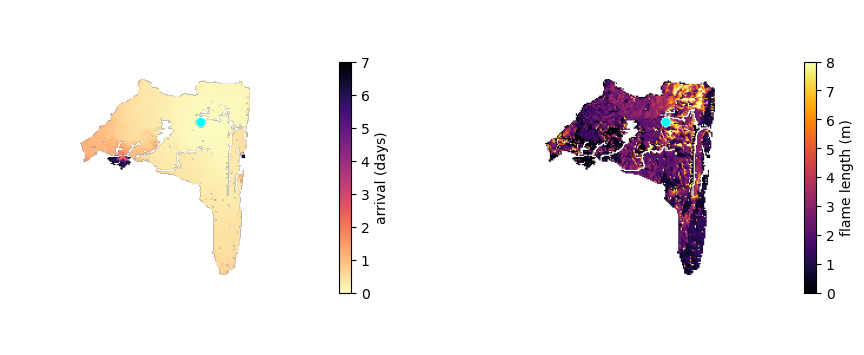

0.6 s | burned 880 ha | max duration reached | pending spot cells 0 | engine 2026.8.10+cfri1


arm                  None
ignition_id       ign_000
episode_id         ep_000
condition_id         None
seed            132185622
burned_ha          880.02
crown_frac         0.6955
fl_p95_m             6.94
fi_p95_kw_m       17561.0
max_toa_h           168.0
firebrands      11.569107
area_d1_ha         819.81
area_d3_ha         869.13
area_d7_ha         880.02
dtype: object

In [8]:
ep0, site = next(iter(frames)), ign.iloc[0]
run_dir = SCRATCH / "runs" / "single" / f"{ep0}_ign_{site.ign_id:03d}"


man = pyre.run_realization(layers, weather_arrays(pd.read_csv(frames[ep0]), wind_cube=cubes[ep0]), site.path, run_dir,
                           seed=pyre.seed_for(SEED, f"ign_{site.ign_id:03d}", ep0, "central"),
                           duration_h=DURATION_DAYS * 24, spot_config=pyre.SPOT_CENTRAL, crown_gate=CROWN_GATE,
                           meta={"ignition_id": f"ign_{site.ign_id:03d}", "episode_id": ep0})


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
with rasterio.open(run_dir / "time_of_arrival.tif") as src:
    im = axes[0].imshow(src.read(1) / 1440.0, extent=rasterio.plot.plotting_extent(src), cmap="magma_r", vmin=0, vmax=DURATION_DAYS)
plt.colorbar(im, ax=axes[0], shrink=0.6, label="arrival (days)"); axes[0].set_axis_off()
show(axes[1], run_dir / "flame_length.tif", "flame length (m)", cmap="inferno", vmin=0, vmax=8)
for ax in axes:
    gpd.read_file(site.path).plot(ax=ax, color="cyan"); zoom(ax, run_dir / "time_of_arrival.tif")
plt.show()
print(f"{man['wall_s']} s | burned {man['burned_ha']:,.0f} ha | {man['stop_condition']} | "
      f"pending spot cells {man['pending_spot_cells']} | engine {man['pyretechnics_version']}")
pd.Series(summarize_realization(run_dir, day_marks=(1, 3, 7, 12, 21)))

### 5b. Counterfactual: a fuel break along a road, over many spotting seeds

One named fire, re-run on landscapes where a corridor along a road has been treated. The ignition point
(`CF_XY`), the start date (`CF_START`) and the duration (`CF_DAYS`) are fixed, so the case is the same on any
machine; what varies is the **spotting seed**, `N_SEEDS` of them. Every seed is shared by every arm, so each
seed is an exactly paired comparison (a sham arm gives Δ = 0; `build_runs` enforces it through
`assert_crn_contract`), and the set of seeds shows how much of an outcome is the treatment and how much is the
draw. A single pair cannot: on one seed of this fire the clear-cut arm ended 2.5× the baseline after a breakout
on day 11 (`docs/pyre_decisions.md`, 2026-11-24).

- **Baseline first** — the baseline arm runs over all seeds; the corridor is cut where those fires went
  (named road within the union of their perimeters + 500 m). Any line set works in place of `feature`: a POD
  boundary, a ridge, a dozer line.
- **Prescriptions** — rows × columns of the tealom effects tables (`canopy_effects.csv`, `surface_effects.csv`):
  a *shaded fuel break* (`Mech Thin` canopy × `Complete` surface) and a *clear cut* (`Patch`: canopy zeroed;
  `Patch_SM`: every fuel → GS1). The road's own non-burnable cells are untouched.
- **Width** — `BREAK_WIDTH_M` in total, centred on the road.

`fuel_break` rasterizes the corridor, applies the prescription with `apply_treatment` and writes a treated LCP;
`destack_lcp` turns each into an engine layer set. `changed_cells` is the treatment as the engine sees it, and
the zone every in-break statistic is read on. Everything this section writes sits under `CF_DIR`, named by its
inputs.

In [ ]:
import hashlib
from shapely.geometry import Point, shape
from rasterio.features import shapes
from fb_tools.fuelscape import fuel_break, build_ignition_footprints
from fb_tools.spread import (changed_cells, near_field_zones, paired_deltas, edge_contact, shadow_agreement,
                             prune_realizations, INTENSITY_EDGES_KW_M, INTENSITY_LABELS)
from fb_tools.suppression import fetch_osm_roads

CF_START      = "2018-06-15"                                 # day 1 of the named episode
CF_XY         = (-793890.0, 1936920.0)                       # ignition point, landscape CRS (EPSG:5070)
CF_DAYS       = 14
N_SEEDS       = 20                                           # spotting seeds, shared by every arm
BREAKOUT_X    = 1.5                                          # breakout: final area > BREAKOUT_X × a median
TEALOM_DATA   = Path("/Users/mcc/Library/CloudStorage/Box-Box/CFRI/RADS/TEALOM/tealom/data")   # effects tables
ROAD_NAMES    = ("Overland Road", "James Canyon Drive")      # the tertiary road the baseline fire crosses
BREAK_WIDTH_M = 300                                          # total corridor width, centred on the road
PRESCRIPTIONS = {"shaded":   {"canopy": "Mech Thin", "surface": "Complete"},
                 "clearcut": {"canopy": "Patch",     "surface": "Patch_SM"}}
CF_DIR        = SCRATCH / "fuel_break"
CF_TAG        = f"{CF_START}_{CF_DAYS}d_{N_SEEDS}seeds_gate{CROWN_GATE}"
canopy_df  = pd.read_csv(TEALOM_DATA / "canopy_effects.csv")
surface_df = pd.read_csv(TEALOM_DATA / "surface_effects.csv")

# weather: the named date as one episode of CF_DAYS, with its own hourly frame and HRRR wind cube
cf_ep = select_episodes(PYROME, ERC_DIR, severity=None, n=None, duration_days=CF_DAYS, dates=[CF_START], rtma_df=rtma)
cf_eid = f"ep_{pd.Timestamp(CF_START):%Y%m%d}_{CF_DAYS}d"
cf_frames = write_episode_frames(cf_ep.assign(episode_id=cf_eid), rtma, CF_DIR / "episodes")
cf_cube = CF_DIR / "episodes" / f"{cf_eid}_wind.npz"
if not cf_cube.exists():
    times = pd.read_csv(cf_frames[cf_eid], parse_dates=["datetime_utc"]).datetime_utc
    write_wind_cube(cf_cube, episode_wind_cube(fetch_hrrr_wind_grid(times, bounds, n_threads=6), TRANSFORM, CRS, SHAPE))

# ignition: a 10-acre footprint on the named point
cf_site = CF_DIR / "ignition" / "ign_cf.shp"
if not cf_site.exists():
    cf_site.parent.mkdir(parents=True, exist_ok=True)
    build_ignition_footprints(gpd.GeoDataFrame({"ign_id": [0]}, geometry=[Point(CF_XY)], crs=CRS),
                              lcp_res_m=abs(TRANSFORM.a)).to_file(cf_site)

# one condition per seed: same settings, different condition id -> different seed, shared by every arm
conditions = {f"seed_{k:02d}": {"spot_config": pyre.SPOT_CENTRAL, "crown_gate": CROWN_GATE} for k in range(N_SEEDS)}
cf = dict(ignitions={"ign_cf": cf_site}, episodes=cf_frames, wind_cubes={cf_eid: cf_cube}, conditions=conditions,
          base_seed=SEED, out_root=CF_DIR / "runs" / f"{CF_DAYS}d")
res_b = pyre.run_batch(pyre.build_runs(arms={"baseline": layers}, **cf), duration_h=CF_DAYS * 24, n_workers=N_WORKERS)

# the corridor: the named road where the baseline fires went
burned = np.zeros(SHAPE, bool)
for d in res_b.out_dir[res_b.status == "ok"]:
    with rasterio.open(Path(d) / "time_of_arrival.tif") as src:
        burned |= np.isfinite(src.read(1))
perim = gpd.GeoSeries([shape(g) for g, _ in shapes(burned.astype("uint8"), mask=burned, transform=TRANSFORM)],
                      crs=CRS).union_all()
roads_fp = CF_DIR / "roads" / f"osm_roads_{CF_TAG}_2km.gpkg"              # named by the fires it was cut around
if not roads_fp.exists():
    roads_fp.parent.mkdir(parents=True, exist_ok=True)
    fetch_osm_roads(gpd.GeoDataFrame(geometry=[perim.buffer(2000)], crs=CRS))[0].to_file(roads_fp, driver="GPKG")
roads = gpd.read_file(roads_fp)
feature = roads[roads.name.isin(ROAD_NAMES)].clip(perim.buffer(500))
print(f"baseline: {int((res_b.status == 'ok').sum())}/{len(res_b)} seeds ok, {burned.sum() * abs(TRANSFORM.a) ** 2 / 1e4:,.0f} ha burned by any seed; "
      f"treating {feature.length.sum() / 1e3:.1f} km of {' / '.join(ROAD_NAMES)} at {BREAK_WIDTH_M} m")

[select_episodes] pool: 1 dates window(s); rank = random
[fetch_hrrr_wind_grid] 336 h, 35x20 cells, 10 missing hour(s) interpolated
  [_assert_grid_congruence] 1 arm(s) congruent: 1000x3000 @ 30 m, EPSG:5070


/var/folders/kf/cn3zpc6d5wq97d5mwv45wf_00000gn/T/ipykernel_30577/2468497400.py:38: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  lcp_res_m=abs(TRANSFORM.a)).to_file(cf_site)
/opt/miniconda3/envs/fb_pyre/lib/python3.11/site-packages/pyogrio/raw.py:723: RuntimeWarning: Normalized/laundered field name: 'footprint_ac' to 'footprint_'
  ogr_write(


[run_batch] 2/20
[run_batch] 4/20
[run_batch] 6/20
[run_batch] 8/20
[run_batch] 10/20
[run_batch] 12/20


In [ ]:
feat_id = hashlib.sha1(feature.union_all().wkb).hexdigest()[:8]            # the corridor's geometry, in the name
arms = {"baseline": layers}
for arm, rx in PRESCRIPTIONS.items():
    tag = f"{LCP_FP.stem}_{arm}_{BREAK_WIDTH_M}m_{feat_id}"               # named by its inputs
    lcp_fp = CF_DIR / "fuelscapes" / f"{tag}.tif"
    if not lcp_fp.exists():
        fuel_break(LCP_FP, feature, BREAK_WIDTH_M, canopy_df, surface_df, rx, out_path=lcp_fp)
    arms[arm] = CF_DIR / "layers" / tag
    if not (arms[arm] / "fuel_model.tif").exists():
        destack_lcp(lcp_fp, arms[arm], verbose=False)
changed = {arm: changed_cells(layers, d) for arm, d in arms.items() if arm != "baseline"}
trt = changed["clearcut"]                                                 # the corridor's burnable cells
zones = near_field_zones(trt, abs(TRANSFORM.a), collar_m=500)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (arm, d) in zip(axes, arms.items()):
    show(ax, d / "fuel_model.tif", f"{arm}: fuel model", cmap="tab20", vmin=90, vmax=190)
    feature.plot(ax=ax, color="r", lw=0.4)
    x0, y0, x1, y1 = feature.total_bounds; ax.set(xlim=(x0 - 1000, x1 + 1000), ylim=(y0 - 1000, y1 + 1000))
plt.show()
print({arm: f"{c.sum() * abs(TRANSFORM.a) ** 2 / 1e4:,.0f} ha changed" for arm, c in changed.items()})

All arms run as one paired table: `build_runs` crosses the arms with the seeds and `run_batch` skips the
baseline rows it already has. `near_field_zones` adds two reporting zones to `summarize_realization`: `trt`
(the corridor) and `collar` (within 500 m of it).

**What is kept.** The per-run table (`summary_*.csv`) and one `BurnProb` raster per arm are written once and
read back on a re-run. Per-run rasters are only needed to make those; the clean-up cell at the end of the
notebook (`prune_realizations`) drops all but arrival time and flame length.

In [ ]:
runs_cf = pyre.build_runs(arms=arms, **cf)
res_cf = pyre.run_batch(runs_cf, duration_h=CF_DAYS * 24, n_workers=N_WORKERS)
ok = res_cf[res_cf.status == "ok"]

out_tag = f"{CF_TAG}_{BREAK_WIDTH_M}m_{feat_id}"
summ_fp = CF_DIR / f"summary_{out_tag}.csv"
if not summ_fp.exists():
    summarize_runs(ok, zones=zones, day_marks=tuple(range(1, CF_DAYS + 1))).to_csv(summ_fp, index=False)
summ = pd.read_csv(summ_fp)
bp_fp = {}
for arm in arms:                                                          # share of seeds that burned each cell
    bp_fp[arm] = CF_DIR / "ensemble" / out_tag / arm / "BurnProb.tif"
    if not bp_fp[arm].exists():
        aggregate_realizations(ok.out_dir, bp_fp[arm].parent, arm=arm, day_marks=(CF_DAYS,), firebrands=False, verbose=False)
summ.groupby("arm")[["burned_ha", *[f"area_d{d}_ha" for d in (1, 3, 7) if d <= CF_DAYS], "fl_p95_m", "firebrands",
                     "trt_arrival_h", "trt_frac_burned", "trt_fi_mean", "collar_fi_mean"]].median().round(1)

**Reading the seeds.** Left: burned area by day for every seed (grey) and the median (black), one panel per
arm. Right: each seed's treated-minus-baseline final area — exact pairs, so a point off zero is the treatment
acting through that seed's fire. The table gives the spread of final size, the **breakout rate** (final area
above `BREAKOUT_X` × the arm's own median, and × the baseline median, which is the one to compare arms on), how
often a treated fire ends larger than its own baseline pair, how many fires reached the domain edge (their size
is truncated), and the fire in the corridor against the hauling-chart classes (hand < 350 kW/m, equipment
< 1,700, indirect < 3,500). The maps are the share of seeds that burned each cell.

In [ ]:
days = np.arange(1, CF_DAYS + 1)
acols = [f"area_d{d}_ha" for d in days]
fig, axes = plt.subplots(1, len(arms) + 1, figsize=(4.2 * (len(arms) + 1), 3.6))
for ax, arm in zip(axes, arms):
    g = summ.loc[summ.arm == arm, acols].to_numpy() / 1e3
    ax.plot(days, g.T, color="0.6", lw=0.6); ax.plot(days, np.median(g, axis=0), color="k", lw=2)
    ax.set(title=arm, xlabel="day", ylabel="burned (k ha)", ylim=(0, summ[acols].max().max() / 1e3 * 1.05))
delta = {arm: paired_deltas(summ, baseline="baseline", treated=arm, cols=["burned_ha"]).d_burned_ha.to_numpy()
         for arm in arms if arm != "baseline"}
rng = np.random.default_rng(0)
for k, (arm, d) in enumerate(delta.items()):
    axes[-1].scatter(k + rng.uniform(-0.12, 0.12, d.size), d / 1e3, s=14, color=f"C{k}")
axes[-1].axhline(0, color="k", lw=0.8)
axes[-1].set(xticks=range(len(delta)), xticklabels=list(delta), xlim=(-0.5, len(delta) - 0.5),
             ylabel="Δ final burned vs baseline pair (k ha)", title=f"{N_SEEDS} exact pairs")
plt.tight_layout(); plt.show()

def hauling(fi):
    return INTENSITY_LABELS[int(np.searchsorted(INTENSITY_EDGES_KW_M, fi))] if np.isfinite(fi) else "unreached"
final = summ.pivot(index="condition_id", columns="arm", values="burned_ha")          # seeds × arms
edge = edge_contact(ok.out_dir).assign(arm=ok.arm.values)
ref = final["baseline"].median()
tab = pd.DataFrame({arm: {
    "final burned, median (ha)": final[arm].median(),
    "final burned, p10 – p90 (ha)": f"{final[arm].quantile(.1):,.0f} – {final[arm].quantile(.9):,.0f}",
    f"breakout rate (> {BREAKOUT_X}× own median)": (final[arm] > BREAKOUT_X * final[arm].median()).mean(),
    f"breakout rate (> {BREAKOUT_X}× baseline median)": (final[arm] > BREAKOUT_X * ref).mean(),
    "seeds larger than their baseline pair": np.nan if arm == "baseline" else (final[arm] > final["baseline"]).mean(),
    "paired Δ final burned, median (ha)": (final[arm] - final["baseline"]).median(),
    "reached the domain edge": edge.loc[edge.arm == arm, "edge_day"].notna().mean(),
    "corridor reached, median (h)": summ.loc[summ.arm == arm, "trt_arrival_h"].median(),
    "mean intensity in break, median (kW/m)": summ.loc[summ.arm == arm, "trt_fi_mean"].median(),
    "hauling class in break": hauling(summ.loc[summ.arm == arm, "trt_fi_mean"].median()),
    "firebrands, median (×1e3)": summ.loc[summ.arm == arm, "firebrands"].median() / 1e3} for arm in arms}).T

bp = {}
for arm, f in bp_fp.items():
    with rasterio.open(f) as src:
        bp[arm], ext = src.read(1), rasterio.plot.plotting_extent(src)
fig, axes = plt.subplots(1, len(arms) + 1, figsize=(4.2 * (len(arms) + 1), 5))
for ax, arm in zip(axes, arms):
    im = ax.imshow(np.where(bp[arm] > 0, bp[arm], np.nan), extent=ext, cmap="YlOrRd", vmin=0, vmax=1); ax.set_title(f"{arm}: share of seeds burned")
im2 = axes[-1].imshow(np.where((bp["clearcut"] > 0) | (bp["baseline"] > 0), bp["clearcut"] - bp["baseline"], np.nan),
                      extent=ext, cmap="RdBu_r", vmin=-1, vmax=1); axes[-1].set_title("clear cut − baseline")
any_burn = np.any([a > 0 for a in bp.values()], axis=0)
rr, cc = np.where(any_burn)
(x0, y1), (x1, y0) = TRANSFORM * (cc.min() - 60, rr.min() - 60), TRANSFORM * (cc.max() + 60, rr.max() + 60)
for ax in axes:
    feature.plot(ax=ax, color="cyan", lw=1); ax.set(xlim=(x0, x1), ylim=(y0, y1)); ax.set_axis_off()
plt.colorbar(im, ax=axes[:-1], shrink=0.6, label="share of seeds"); plt.colorbar(im2, ax=axes[-1], shrink=0.6, label="Δ share")
plt.show()
tab

**Where the treatment could act.** The treatment shadow is read off the **baseline** arm: the share of the fire
reaching each cell that had passed over the corridor's footprint. `shadow_agreement` scores it, seed by seed,
against the cells whose arrival actually changed between the arms (treated cells left out): *recall* is the
share of changed cells inside the shadow, *precision* the share of shadow cells that changed. High on both, the
shadow is a fair stratifier for the paired deltas; low recall means the treated fire went somewhere the baseline
fire never did, which a baseline shadow cannot see.

In [ ]:
dirs = ok.pivot(index="condition_id", columns="arm", values="out_dir")
agree = pd.concat([shadow_agreement(r["baseline"], r[arm], trt, tolerances_min=(10.0, 60.0))
                   for _, r in dirs.dropna().iterrows() for arm in arms if arm != "baseline"])
agree.groupby(["treated", "tol_min"])[["recall", "precision", "auc"]].agg(["median", "min", "max"]).round(2)

**How to read it, and what to change.** One seed is one draw; the answer is the distribution. A break that
lowers intensity in the corridor in every seed but leaves final size unchanged is a place to hold a line, not a
line that holds itself — the stepped runner's containment rule (`run_realization(step_h=..., suppression=...)`)
is how to test that. A treated arm with a higher breakout rate than the baseline is worth tracing before it is
believed: check when the arms part (the growth curves), whether the fires reached the domain edge, and whether
the extra area is ember-started (`ember_descent`).

Only the spotting seed varies here. Whether the result holds for other ignition points, start hours or
episodes is the next experiment: add ignitions or episodes to `cf` and the same cells run unchanged. The other
knobs are `ROAD_NAMES` (or any line GeoDataFrame in place of `feature`), `BREAK_WIDTH_M` and `PRESCRIPTIONS`;
a width or prescription sweep is one more arm per value.

## 6. Ensemble → probabilistic surfaces

`build_runs` crosses every ignition × episode × condition (× arm) into one table, with a deterministic seed
per (ignition, episode, condition). The seed never depends on the arm, so adding a treated landscape later
gives exactly paired runs. `run_batch` runs the table in a spawn pool and skips rows whose manifest already
exists. `aggregate_realizations` streams the results into

- **BurnProb** — fraction of realizations that burned the cell;
- **ArrivalProb_d{d}** — fraction that reached the cell by day *d*: the probabilistic arrival-time surface;
- **AvgTime**, **AvgFlameLength** — mean arrival day and flame length where burned;
- **Firebrands** — expected firebrands produced per cell, averaged over realizations: the engine's production
  formula (*f* · 60 *I* / *R* · cell area) read off each realization's intensity and spread-rate rasters. This
  is a spot-fire **source** map; realized ember landings are not exposed by the engine's final matrices.

With one arm and sites drawn ∝ density these are probabilities over ignition location and over `SEVERITY`
weather, conditional on a fire starting on day 1 of a severe episode.

In [ ]:
runs = pyre.build_runs(arms={"baseline": layers},
                       ignitions={f"ign_{i:03d}": p for i, p in zip(ign.ign_id, ign.path)},
                       episodes=frames, wind_cubes=cubes,
                       conditions={"central": {"spot_config": pyre.SPOT_CENTRAL, "crown_gate": CROWN_GATE}},
                       base_seed=SEED, out_root=SCRATCH / "runs" / "ensemble")
print(len(runs), "realizations =", ign.shape[0], "sites ×", len(frames), "episodes")
t0 = time.perf_counter()
res = pyre.run_batch(runs, duration_h=DURATION_DAYS * 24, n_workers=N_WORKERS)
print(f"{(time.perf_counter() - t0) / 60:.1f} min wall on {N_WORKERS} workers")
ens_dir = SCRATCH / "ensemble" / f"{SEVERITY}_{DURATION_DAYS}d_{len(runs)}runs_gate{CROWN_GATE}"   # named by its inputs
ens_dir.mkdir(parents=True, exist_ok=True)
if not (ens_dir / "summary.csv").exists():
    summarize_runs(res, day_marks=(1, 3, 7, 15, 21)).to_csv(ens_dir / "summary.csv", index=False)
summary = pd.read_csv(ens_dir / "summary.csv")
summary[["burned_ha", "area_d1_ha", "area_d3_ha", "fl_p95_m", "firebrands"]].describe(percentiles=[.5, .9]).round(1)

In [ ]:
agg = {f.stem: f for f in ens_dir.glob("*.tif")}                          # written once, read back on a re-run
if "BurnProb" not in agg:
    agg = aggregate_realizations(res.loc[res.status == "ok", "out_dir"], ens_dir, arm="baseline", day_marks=(1, 3, 7))

fig, axes = plt.subplots(2, 3, figsize=(13, 13))
show(axes[0, 0], agg["BurnProb"], "burn probability", mask_zero=True, cmap="YlOrRd")
ign.plot(ax=axes[0, 0], color="none", edgecolor="b", lw=0.6)
show(axes[0, 1], agg["ArrivalProb_d1"], "P(arrival ≤ day 1)", mask_zero=True, cmap="YlOrRd")
show(axes[0, 2], agg["ArrivalProb_d3"], "P(arrival ≤ day 3)", mask_zero=True, cmap="YlOrRd")
show(axes[1, 0], agg["AvgTime"], "mean arrival (days, where burned)", cmap="magma_r", vmin=0, vmax=DURATION_DAYS)
show(axes[1, 1], agg["AvgFlameLength"], "mean flame length (m)", cmap="inferno", vmin=0, vmax=8)
show(axes[1, 2], agg["Firebrands"], "expected firebrands per cell (log)", mask_zero=True, cmap="cividis", norm=LogNorm())
plt.show()
with rasterio.open(agg["BurnProb"]) as src:
    bp = src.read(1)
print(f"BurnProb > 0 on {(bp > 0).sum() * 0.09:,.0f} ha; mean fire size {summary.burned_ha.mean():,.0f} ha; "
      f"Σ BP × area = {bp.sum() * 0.09:,.0f} ha (the two agree by construction)")

## 7. Diagnostics

Three checks before the surfaces above are read: how many fires were truncated by the domain edge and when;
whether fire size is set by the site or the episode; and whether two random halves of the sites agree on
`BurnProb`. The ensemble is large enough when the half-to-half difference is smaller than the effect you want
to read, and only meaningful when few fires reach the edge.

In [ ]:
# Diagnostics: is the ensemble readable? (edge truncation, site vs episode, split-half convergence)
from fb_tools.spread import edge_contact
ok = res[res.status == "ok"]
e = edge_contact(ok.out_dir).assign(ignition_id=ok.ignition_id.values, episode_id=ok.episode_id.values)
e["log_ha"] = np.log(e.burned_ha)
g = e.log_ha.mean(); ss = ((e.log_ha - g) ** 2).sum()
site_share = ((e.groupby("ignition_id").log_ha.transform("mean") - g) ** 2).sum() / ss
ep_share = ((e.groupby("episode_id").log_ha.transform("mean") - g) ** 2).sum() / ss
half = set(np.random.default_rng(0).choice(sorted(e.ignition_id.unique()), e.ignition_id.nunique() // 2, replace=False))
bp = {}
for name, sub in (("A", e[e.ignition_id.isin(half)]), ("B", e[~e.ignition_id.isin(half)])):
    with rasterio.open(aggregate_realizations(sub.out_dir, ens_dir / f"half_{name}", firebrands=False, verbose=False)["BurnProb"]) as src:
        bp[name] = src.read(1)
m = (bp["A"] > 0) | (bp["B"] > 0); dbp = np.abs(bp["A"] - bp["B"])[m]
days = np.arange(1, DURATION_DAYS + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(days, [(e.edge_day <= d).mean() * 100 for d in days], marker="o", color="C3"); axes[0].set(xlabel="day", ylabel="% of fires at the domain edge", ylim=(0, 100))
order = e.groupby("ignition_id").burned_ha.mean().sort_values().index
axes[1].scatter(e.ignition_id.map({s: i for i, s in enumerate(order)}), e.burned_ha / 1e3, s=8, c=np.where(e.edge_day.notna(), "C3", "C0"))
axes[1].set(xlabel="site (sorted by mean size)", ylabel="fire size (k ha)", title=f"site {site_share:.0%} / episode {ep_share:.0%} of log-size variance", )
axes[2].hist(dbp, bins=40, color="0.6"); axes[2].set(xlabel="|BurnProb(half A) − BurnProb(half B)|", ylabel="cells", title=f"p90 {np.quantile(dbp, .9):.3f} vs median BP {np.median(bp['A'][m] + bp['B'][m]) / 2:.3f}")
plt.tight_layout(); plt.show()
print(f"edge contact by day {DURATION_DAYS}: {e.edge_day.notna().mean():.0%} (red points) | no-spread: {(e.burned_ha < 1).sum()}")

## 8. Clean up

Per-run rasters are intermediate: the summaries and ensemble rasters above are what the notebook reads back.
`prune_realizations` deletes every per-run layer except the ones named in `keep` (arrival time for the growth,
shadow and edge diagnostics; flame length so an ensemble can be re-aggregated) and records what it removed in
each manifest. `run_batch` still treats a pruned run as done; a cell that needs a removed layer says so, and
`overwrite=True` on the run brings it back.

In [ ]:
KEEP = ("time_of_arrival", "flame_length")
prune_realizations(res_cf.out_dir, keep=KEEP)
prune_realizations(res.out_dir, keep=KEEP)

## Next

- **This ensemble is a method test, not a product.** Reviewed 2026-09-13: 87% of these fires reached the domain
  edge (35% on day 1 — the AOI is a 30 × 90 km strip), the site explains 85% of fire-size variance and the episode
  2%, and two random halves of the sites disagree on `BurnProb` by more than its median. The blocky surface is
  ~100 truncated footprints each stamped 5×. The diagnostics above make that visible; run them on any ensemble.
- **Domain and duration first, realizations second.** Choose `DURATION_DAYS` so that few fires touch the edge
  (`edge_contact`), or widen the landscape, before raising `N_IGNITIONS`; then judge convergence by the split-half
  comparison. Sites matter more than episodes here.
- **What the surface means:** P(cell burns | a fire starts on day 1 of a `SEVERITY` episode at a density-drawn
  site and burns `DURATION_DAYS` unsuppressed) — a conditional exposure surface, not an annual burn probability.
- **Counterfactual and transmission products** live in the COSWAP project notebook: paired arms over the
  ensemble, the treatment shadow, per-block interception. §5b is the one-fire, many-seeds version of that
  pairing; its arms go through §6 unchanged (`aggregate_realizations(..., arm=...)` is one arm per call, and the
  shadow is read off the baseline arm). Spotting on/off and crown-gate sensitivity tests belong here, on this
  landscape.